## Installing libraries

In [5]:
!pip -q install torch-geometric shap scikit-learn pandas numpy matplotlib seaborn

## Importing libraries and setting reproducibility

In [6]:

import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score
)

from torch_geometric.nn import GCNConv, global_mean_pool

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Device:", device)


PyTorch version: 2.11.0+cu130
Device: cuda


## Loading the CSV

In [7]:

from google.colab import files

uploaded = files.upload()

csv_file = next(
    name for name in uploaded.keys()
    if name.lower().endswith(".csv")
)

df = pd.read_csv(csv_file)

print("Dataset shape:", df.shape)
display(df.head())
print("\nColumn names:")
print(df.columns.tolist())


Saving creditcard.csv to creditcard.csv
Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0



Column names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


## Inspecting the target distribution

Missing values: 0

Class distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Class proportions:
Class
0    0.998273
1    0.001727
Name: proportion, dtype: float64


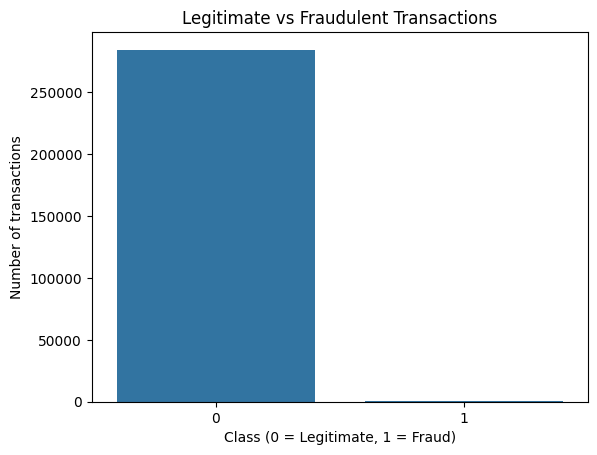

In [8]:

print("Missing values:", df.isnull().sum().sum())
print("\nClass distribution:")
print(df["Class"].value_counts())

print("\nClass proportions:")
print(df["Class"].value_counts(normalize=True))

sns.countplot(data=df, x="Class")
plt.title("Legitimate vs Fraudulent Transactions")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of transactions")
plt.show()


## Selecting the features and splitting the dataset

In [9]:

selected_features = [
    "V14", "V10", "V4", "V17", "V12",
    "V11", "V16", "V8", "V3", "V1"
]

X = df[selected_features].copy()
y = df["Class"].astype("int64").copy()

print("Selected features:", selected_features)
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val,
    test_size=0.10,
    random_state=42,
    stratify=y_train_val
)

print("\nTraining samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

print("\nFraud cases in each split:")
print("Train:", int(y_train.sum()))
print("Validation:", int(y_val.sum()))
print("Test:", int(y_test.sum()))


Selected features: ['V14', 'V10', 'V4', 'V17', 'V12', 'V11', 'V16', 'V8', 'V3', 'V1']
Feature matrix shape: (284807, 10)
Target shape: (284807,)

Training samples: 205060
Validation samples: 22785
Testing samples: 56962

Fraud cases in each split:
Train: 355
Validation: 39
Test: 98


## Scaling the features

In [10]:

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train).astype(np.float32)
X_val_scaled = scaler.transform(X_val).astype(np.float32)
X_test_scaled = scaler.transform(X_test).astype(np.float32)

y_train_np = y_train.to_numpy(dtype=np.int64)
y_val_np = y_val.to_numpy(dtype=np.int64)
y_test_np = y_test.to_numpy(dtype=np.int64)

print("Train:", X_train_scaled.shape, y_train_np.shape)
print("Validation:", X_val_scaled.shape, y_val_np.shape)
print("Test:", X_test_scaled.shape, y_test_np.shape)

print("\nScaled training feature means:")
print(np.round(X_train_scaled.mean(axis=0), 3))


Train: (205060, 10) (205060,)
Validation: (22785, 10) (22785,)
Test: (56962, 10) (56962,)

Scaled training feature means:
[-0. -0. -0. -0. -0.  0.  0. -0. -0. -0.]


## Preparing PyTorch DataLoaders

In [11]:

X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train_np, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val_np, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test_np, dtype=torch.float32)

BATCH_SIZE = 512

train_loader = DataLoader(
    TensorDataset(X_train_tensor, y_train_tensor),
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    TensorDataset(X_val_tensor, y_val_tensor),
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    TensorDataset(X_test_tensor, y_test_tensor),
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))


Training batches: 401
Validation batches: 45
Test batches: 112


## Defining CNN architechture

In [12]:

class CNNFraudDetector(nn.Module):
    def __init__(self, input_features=10):
        super().__init__()

        self.conv_layers = nn.Sequential(
            nn.Conv1d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),

            nn.Conv1d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),

            nn.Conv1d(64, 64, kernel_size=3, padding=1),
            nn.ReLU()
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 2, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        # (batch_size, 10) -> (batch_size, 1, 10)
        x = x.unsqueeze(1)
        x = self.conv_layers(x)
        return self.classifier(x).squeeze(1)


cnn_model = CNNFraudDetector().to(device)

print(cnn_model)
print("\nDevice:", device)


CNNFraudDetector(
  (conv_layers): Sequential(
    (0): Conv1d(1, 32, kernel_size=(3,), stride=(1,), padding=(1,))
    (1): ReLU()
    (2): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv1d(32, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (4): ReLU()
    (5): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (7): ReLU()
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=128, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=1, bias=True)
  )
)

Device: cuda


## Configuring the training process

In [13]:

positive_count = int(y_train_np.sum())
negative_count = len(y_train_np) - positive_count

pos_weight = torch.tensor(
    [negative_count / positive_count],
    dtype=torch.float32,
    device=device
)

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

optimizer = torch.optim.Adam(
    cnn_model.parameters(),
    lr=0.001
)

print("Fraud cases in training:", positive_count)
print("Legitimate cases in training:", negative_count)
print("Positive class weight:", pos_weight.item())


Fraud cases in training: 355
Legitimate cases in training: 204705
Positive class weight: 576.6337890625


## Training CNN with early stopping

In [14]:

MAX_EPOCHS = 15
PATIENCE = 3

best_val_loss = float("inf")
patience_counter = 0
best_cnn_state = None

history = {
    "train_loss": [],
    "val_loss": []
}

for epoch in range(MAX_EPOCHS):
    cnn_model.train()
    total_train_loss = 0.0

    for xb, yb in train_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()

        logits = cnn_model(xb)
        loss = criterion(logits, yb)

        loss.backward()
        optimizer.step()

        total_train_loss += loss.item() * len(xb)

    train_loss = total_train_loss / len(train_loader.dataset)

    cnn_model.eval()
    total_val_loss = 0.0

    with torch.no_grad():
        for xb, yb in val_loader:
            xb = xb.to(device)
            yb = yb.to(device)

            logits = cnn_model(xb)
            loss = criterion(logits, yb)

            total_val_loss += loss.item() * len(xb)

    val_loss = total_val_loss / len(val_loader.dataset)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    print(
        f"Epoch {epoch + 1:02d}/{MAX_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        patience_counter = 0
        best_cnn_state = {
            k: v.detach().cpu().clone()
            for k, v in cnn_model.state_dict().items()
        }
    else:
        patience_counter += 1

        if patience_counter >= PATIENCE:
            print("Early stopping triggered.")
            break

cnn_model.load_state_dict(best_cnn_state)
cnn_model.to(device)

print("Best validation loss:", best_val_loss)


Epoch 01/15 | Train Loss: 0.4978 | Val Loss: 0.4211
Epoch 02/15 | Train Loss: 0.3195 | Val Loss: 0.5273
Epoch 03/15 | Train Loss: 0.2916 | Val Loss: 0.4715
Epoch 04/15 | Train Loss: 0.3258 | Val Loss: 0.4774
Early stopping triggered.
Best validation loss: 0.4211261430408234


## Plotting the training curve

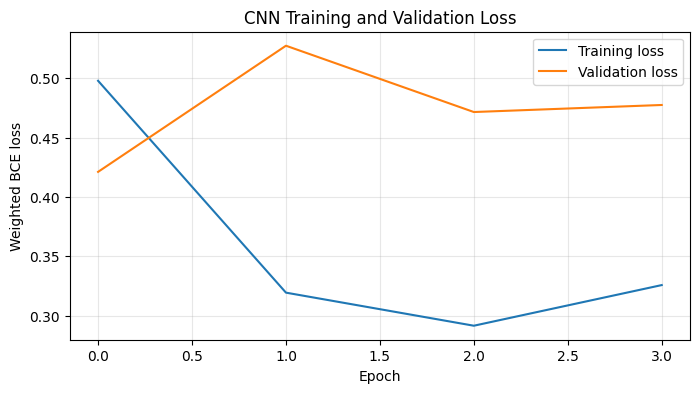

In [15]:

plt.figure(figsize=(8, 4))

plt.plot(history["train_loss"], label="Training loss")
plt.plot(history["val_loss"], label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Weighted BCE loss")
plt.title("CNN Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


## Evaluating the CNN

CNN Test Results (threshold = 0.5)
----------------------------------------
Accuracy: 0.9539693128752502
Precision: 0.03328402366863906
Recall: 0.9183673469387755
F1-score: 0.06423982869379015
ROC-AUC: 0.9795588184626692
PR-AUC (Average Precision): 0.7073405732289271

Classification report:
              precision    recall  f1-score   support

  Legitimate       1.00      0.95      0.98     56864
       Fraud       0.03      0.92      0.06        98

    accuracy                           0.95     56962
   macro avg       0.52      0.94      0.52     56962
weighted avg       1.00      0.95      0.97     56962



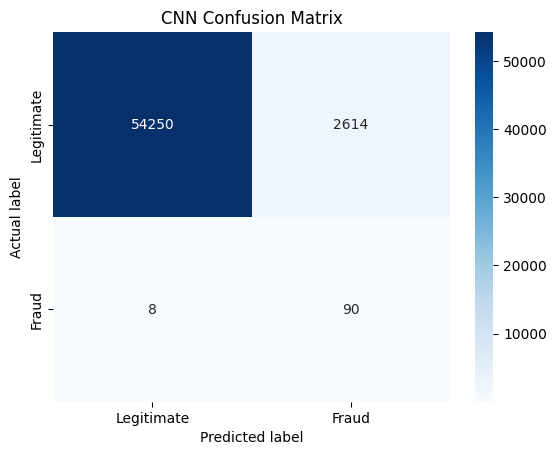

In [16]:

def get_probabilities(model, loader):
    model.eval()
    probabilities = []

    with torch.no_grad():
        for xb, _ in loader:
            xb = xb.to(device)
            logits = model(xb)
            probs = torch.sigmoid(logits)
            probabilities.extend(probs.cpu().numpy())

    return np.asarray(probabilities)


cnn_val_probs = get_probabilities(cnn_model, val_loader)
cnn_test_probs = get_probabilities(cnn_model, test_loader)

cnn_test_preds = (cnn_test_probs >= 0.5).astype(int)

print("CNN Test Results (threshold = 0.5)")
print("-" * 40)
print("Accuracy:",
      accuracy_score(y_test_np, cnn_test_preds))
print("Precision:",
      precision_score(y_test_np, cnn_test_preds, zero_division=0))
print("Recall:",
      recall_score(y_test_np, cnn_test_preds, zero_division=0))
print("F1-score:",
      f1_score(y_test_np, cnn_test_preds, zero_division=0))
print("ROC-AUC:",
      roc_auc_score(y_test_np, cnn_test_probs))
print("PR-AUC (Average Precision):",
      average_precision_score(y_test_np, cnn_test_probs))

print("\nClassification report:")
print(classification_report(
    y_test_np,
    cnn_test_preds,
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))

cm = confusion_matrix(y_test_np, cnn_test_preds)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("CNN Confusion Matrix")
plt.show()


## Defining RNN and LSTM

In [17]:

class RNNFraudDetector(nn.Module):
    def __init__(self, hidden_size=128):
        super().__init__()

        self.rnn = nn.RNN(
            input_size=1,
            hidden_size=hidden_size,
            num_layers=2,
            nonlinearity="tanh",
            batch_first=True,
            dropout=0.2
        )

        self.classifier = nn.Sequential(
            nn.Linear(hidden_size, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        # Treat the 10 selected features as a sequence
        x = x.unsqueeze(-1)  # (batch, 10, 1)
        _, hidden = self.rnn(x)
        return self.classifier(hidden[-1]).squeeze(1)


class LSTMFraudDetector(nn.Module):
    def __init__(self, hidden_size=128):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=1,
            hidden_size=hidden_size,
            num_layers=2,
            batch_first=True,
            dropout=0.3
        )

        self.classifier = nn.Sequential(
            nn.Linear(hidden_size, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        x = x.unsqueeze(-1)  # (batch, 10, 1)
        _, (hidden, _) = self.lstm(x)
        return self.classifier(hidden[-1]).squeeze(1)


rnn_model = RNNFraudDetector().to(device)
lstm_model = LSTMFraudDetector().to(device)

print("RNN parameters:",
      sum(p.numel() for p in rnn_model.parameters()))

print("LSTM parameters:",
      sum(p.numel() for p in lstm_model.parameters()))


RNN parameters: 58113
LSTM parameters: 207489


## Creating a reusable training function

In [18]:

def train_model(
    model,
    train_loader,
    val_loader,
    learning_rate=0.001,
    max_epochs=15,
    patience=3
):
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    best_loss = float("inf")
    best_state = None
    wait = 0

    history = {"train_loss": [], "val_loss": []}

    for epoch in range(max_epochs):
        model.train()
        train_total = 0.0

        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)

            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()

            train_total += loss.item() * len(xb)

        train_loss = train_total / len(train_loader.dataset)

        model.eval()
        val_total = 0.0

        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                loss = criterion(model(xb), yb)
                val_total += loss.item() * len(xb)

        val_loss = val_total / len(val_loader.dataset)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        print(
            f"Epoch {epoch + 1:02d}/{max_epochs} | "
            f"Train: {train_loss:.4f} | "
            f"Validation: {val_loss:.4f}"
        )

        if val_loss < best_loss:
            best_loss = val_loss
            wait = 0

            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }
        else:
            wait += 1
            if wait >= patience:
                print("Early stopping.")
                break

    model.load_state_dict(best_state)
    model.to(device)

    return model, history


## Training the RNN

In [19]:

def train_rnn_model(
    model, train_loader, val_loader,
    learning_rate=0.001, max_epochs=15, patience=3
):
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimizer = torch.optim.RMSprop(
        model.parameters(), lr=learning_rate
    )

    best_loss = float("inf")
    best_state = None
    wait = 0
    history = {"train_loss": [], "val_loss": []}

    for epoch in range(max_epochs):
        model.train()
        total = 0.0

        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            total += loss.item() * len(xb)

        train_loss = total / len(train_loader.dataset)

        model.eval()
        val_total = 0.0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                val_total += criterion(model(xb), yb).item() * len(xb)

        val_loss = val_total / len(val_loader.dataset)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        print(
            f"Epoch {epoch+1:02d}/{max_epochs} | "
            f"Train: {train_loss:.4f} | Val: {val_loss:.4f}"
        )

        if val_loss < best_loss:
            best_loss = val_loss
            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print("Early stopping.")
                break

    model.load_state_dict(best_state)
    model.to(device)
    return model, history


rnn_model, rnn_history = train_rnn_model(
    rnn_model, train_loader, val_loader
)


Epoch 01/15 | Train: 0.4912 | Val: 0.5650
Epoch 02/15 | Train: 0.4234 | Val: 0.5815
Epoch 03/15 | Train: 0.4405 | Val: 0.6569
Epoch 04/15 | Train: 0.4072 | Val: 0.6884
Early stopping.


## Training the LSTM

In [20]:

lstm_model, lstm_history = train_model(
    lstm_model,
    train_loader,
    val_loader,
    learning_rate=0.0005,
    max_epochs=15,
    patience=3
)


Epoch 01/15 | Train: 0.5999 | Validation: 0.6296
Epoch 02/15 | Train: 0.4653 | Validation: 0.6734
Epoch 03/15 | Train: 0.4512 | Validation: 0.5631
Epoch 04/15 | Train: 0.4137 | Validation: 0.6152
Epoch 05/15 | Train: 0.4232 | Validation: 0.5409
Epoch 06/15 | Train: 0.4056 | Validation: 0.5461
Epoch 07/15 | Train: 0.4120 | Validation: 0.5263
Epoch 08/15 | Train: 0.3904 | Validation: 0.5569
Epoch 09/15 | Train: 0.3977 | Validation: 0.5595
Epoch 10/15 | Train: 0.3924 | Validation: 0.4672
Epoch 11/15 | Train: 0.3729 | Validation: 0.4466
Epoch 12/15 | Train: 0.3542 | Validation: 0.4767
Epoch 13/15 | Train: 0.3555 | Validation: 0.5365
Epoch 14/15 | Train: 0.3550 | Validation: 0.4820
Early stopping.


## Evaluating all three models consistently

In [21]:

models = {
    "CNN": cnn_model,
    "RNN": rnn_model,
    "LSTM": lstm_model
}

results = []

for name, model in models.items():
    probs = get_probabilities(model, test_loader)
    preds = (probs >= 0.5).astype(int)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_np, preds),
        "Precision": precision_score(
            y_test_np, preds, zero_division=0
        ),
        "Recall": recall_score(
            y_test_np, preds, zero_division=0
        ),
        "F1-score": f1_score(
            y_test_np, preds, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test_np, probs),
        "PR-AUC": average_precision_score(y_test_np, probs)
    })

    print(f"\n{name} classification report:")
    print(classification_report(
        y_test_np, preds,
        target_names=["Legitimate", "Fraud"],
        zero_division=0
    ))

model_comparison = pd.DataFrame(results)
display(model_comparison.round(4))



CNN classification report:
              precision    recall  f1-score   support

  Legitimate       1.00      0.95      0.98     56864
       Fraud       0.03      0.92      0.06        98

    accuracy                           0.95     56962
   macro avg       0.52      0.94      0.52     56962
weighted avg       1.00      0.95      0.97     56962


RNN classification report:
              precision    recall  f1-score   support

  Legitimate       1.00      0.97      0.98     56864
       Fraud       0.05      0.90      0.09        98

    accuracy                           0.97     56962
   macro avg       0.52      0.93      0.54     56962
weighted avg       1.00      0.97      0.98     56962


LSTM classification report:
              precision    recall  f1-score   support

  Legitimate       1.00      0.97      0.99     56864
       Fraud       0.05      0.89      0.10        98

    accuracy                           0.97     56962
   macro avg       0.53      0.93      0.54

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,CNN,0.9540,0.0333,0.9184,0.0642,0.9796,0.7073
1,RNN,0.9682,0.0466,0.8980,0.0886,0.9771,0.5740
2,LSTM,0.9721,0.0523,0.8878,0.0988,0.9617,0.7033


## Building the graph and defining the GNN

In [22]:

from torch_geometric.nn import GCNConv

def build_knn_edge_index(x, k=5):
    """
    Build a directed k-nearest-neighbor graph
    using feature-space Euclidean distance.
    x: tensor of shape (number_of_nodes, number_of_features)
    """
    n = x.size(0)
    k = min(k, n - 1)

    with torch.no_grad():
        distances = torch.cdist(x, x)
        distances.fill_diagonal_(float("inf"))

        neighbors = distances.topk(
            k=k, dim=1, largest=False
        ).indices

        target = torch.arange(
            n, device=x.device
        ).repeat_interleave(k)

        source = neighbors.reshape(-1)

        edge_index = torch.stack([source, target], dim=0)

    return edge_index


class GNNFraudDetector(nn.Module):
    def __init__(self, input_features=10, hidden_size=64):
        super().__init__()

        self.conv1 = GCNConv(input_features, hidden_size)
        self.conv2 = GCNConv(hidden_size, hidden_size)
        self.conv3 = GCNConv(hidden_size, hidden_size)

        self.dropout = nn.Dropout(0.2)
        self.output_layer = nn.Linear(hidden_size, 1)

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = torch.nn.functional.leaky_relu(x)
        x = self.dropout(x)

        x = self.conv2(x, edge_index)
        x = torch.nn.functional.leaky_relu(x)
        x = self.dropout(x)

        x = self.conv3(x, edge_index)
        x = torch.nn.functional.leaky_relu(x)

        return self.output_layer(x).squeeze(-1)


gnn_model = GNNFraudDetector().to(device)

print(gnn_model)
print("GNN device:", device)


GNNFraudDetector(
  (conv1): GCNConv(10, 64)
  (conv2): GCNConv(64, 64)
  (conv3): GCNConv(64, 64)
  (dropout): Dropout(p=0.2, inplace=False)
  (output_layer): Linear(in_features=64, out_features=1, bias=True)
)
GNN device: cuda


## Training the GNN

In [23]:

def train_gnn(model, max_epochs=10, patience=3):
    optimizer = torch.optim.Adam(
        model.parameters(), lr=0.001
    )
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

    best_loss = float("inf")
    best_state = None
    wait = 0

    for epoch in range(max_epochs):
        model.train()
        train_total = 0.0

        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)

            # Build a graph within this batch
            edge_index = build_knn_edge_index(xb, k=5)

            optimizer.zero_grad()
            logits = model(xb, edge_index)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()

            train_total += loss.item() * len(xb)

        train_loss = train_total / len(train_loader.dataset)

        model.eval()
        val_total = 0.0

        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                edge_index = build_knn_edge_index(xb, k=5)

                logits = model(xb, edge_index)
                loss = criterion(logits, yb)

                val_total += loss.item() * len(xb)

        val_loss = val_total / len(val_loader.dataset)

        print(
            f"Epoch {epoch+1:02d}/{max_epochs} | "
            f"Train: {train_loss:.4f} | "
            f"Validation: {val_loss:.4f}"
        )

        if val_loss < best_loss:
            best_loss = val_loss
            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print("Early stopping.")
                break

    model.load_state_dict(best_state)
    model.to(device)
    return model


train_loader = DataLoader(
    TensorDataset(X_train_tensor, y_train_tensor),
    batch_size=256, shuffle=True
)

val_loader = DataLoader(
    TensorDataset(X_val_tensor, y_val_tensor),
    batch_size=256, shuffle=False
)

test_loader = DataLoader(
    TensorDataset(X_test_tensor, y_test_tensor),
    batch_size=256, shuffle=False
)

gnn_model = train_gnn(gnn_model)


Epoch 01/10 | Train: 0.8290 | Validation: 0.8294
Epoch 02/10 | Train: 0.6093 | Validation: 0.8978
Epoch 03/10 | Train: 0.5539 | Validation: 0.8485
Epoch 04/10 | Train: 0.5033 | Validation: 0.6522
Epoch 05/10 | Train: 0.4263 | Validation: 0.6181
Epoch 06/10 | Train: 0.4182 | Validation: 0.5635
Epoch 07/10 | Train: 0.4138 | Validation: 0.5742
Epoch 08/10 | Train: 0.3909 | Validation: 0.5424
Epoch 09/10 | Train: 0.3958 | Validation: 0.5055
Epoch 10/10 | Train: 0.3831 | Validation: 0.4985


## Generating GNN predictions

In [24]:

def get_gnn_probabilities(model, loader):
    model.eval()
    all_probs = []

    with torch.no_grad():
        for xb, _ in loader:
            xb = xb.to(device)
            edge_index = build_knn_edge_index(xb, k=5)

            logits = model(xb, edge_index)
            probs = torch.sigmoid(logits)

            all_probs.extend(probs.cpu().numpy())

    return np.asarray(all_probs)


gnn_val_probs = get_gnn_probabilities(gnn_model, val_loader)
gnn_test_probs = get_gnn_probabilities(gnn_model, test_loader)

gnn_test_preds = (gnn_test_probs >= 0.5).astype(int)

print("GNN Test Results")
print("Accuracy:", accuracy_score(y_test_np, gnn_test_preds))
print("Precision:", precision_score(
    y_test_np, gnn_test_preds, zero_division=0
))
print("Recall:", recall_score(
    y_test_np, gnn_test_preds, zero_division=0
))
print("F1-score:", f1_score(
    y_test_np, gnn_test_preds, zero_division=0
))
print("ROC-AUC:", roc_auc_score(y_test_np, gnn_test_probs))
print("PR-AUC:", average_precision_score(y_test_np, gnn_test_probs))


GNN Test Results
Accuracy: 0.9711562094027597
Precision: 0.0506108202443281
Recall: 0.8877551020408163
F1-score: 0.0957622454595487
ROC-AUC: 0.9659297191724185
PR-AUC: 0.5235081560366039


## Generating aligned predictions

In [25]:
from torch.utils.data import DataLoader, TensorDataset

train_eval_loader = DataLoader(
    TensorDataset(X_train_tensor, torch.tensor(y_train_np, dtype=torch.float32)),
    batch_size=256, shuffle=False
)

val_eval_loader = DataLoader(
    TensorDataset(X_val_tensor, torch.tensor(y_val_np, dtype=torch.float32)),
    batch_size=256, shuffle=False
)

test_eval_loader = DataLoader(
    TensorDataset(X_test_tensor, torch.tensor(y_test_np, dtype=torch.float32)),
    batch_size=256, shuffle=False
)

print("Ordered evaluation loaders created.")

Ordered evaluation loaders created.


## Getting predictions from all four models

In [26]:
def collect_all_probabilities(loader):
    cnn_probs = get_probabilities(cnn_model, loader)
    rnn_probs = get_probabilities(rnn_model, loader)
    lstm_probs = get_probabilities(lstm_model, loader)
    gnn_probs = get_gnn_probabilities(gnn_model, loader)

    return {
        "CNN": cnn_probs,
        "RNN": rnn_probs,
        "LSTM": lstm_probs,
        "GNN": gnn_probs
    }

train_probs = collect_all_probabilities(train_eval_loader)
val_probs = collect_all_probabilities(val_eval_loader)
test_probs = collect_all_probabilities(test_eval_loader)

print("Train predictions:", {
    name: len(probs) for name, probs in train_probs.items()
})
print("Validation predictions:", {
    name: len(probs) for name, probs in val_probs.items()
})
print("Test predictions:", {
    name: len(probs) for name, probs in test_probs.items()
})

Train predictions: {'CNN': 205060, 'RNN': 205060, 'LSTM': 205060, 'GNN': 205060}
Validation predictions: {'CNN': 22785, 'RNN': 22785, 'LSTM': 22785, 'GNN': 22785}
Test predictions: {'CNN': 56962, 'RNN': 56962, 'LSTM': 56962, 'GNN': 56962}


## Implementing DOWA fusion

In [27]:
def dowa_fusion(p1, p2, eps=1e-8):
    mean_prob = (p1 + p2) / 2

    similarity1 = 1 / (np.abs(p1 - mean_prob) + eps)
    similarity2 = 1 / (np.abs(p2 - mean_prob) + eps)

    weight1 = similarity1 / (similarity1 + similarity2)
    weight2 = similarity2 / (similarity1 + similarity2)

    return weight1 * p1 + weight2 * p2


dowa_train = dowa_fusion(train_probs["CNN"], train_probs["RNN"])
dowa_val = dowa_fusion(val_probs["CNN"], val_probs["RNN"])
dowa_test = dowa_fusion(test_probs["CNN"], test_probs["RNN"])

print("DOWA fusion completed.")
print("First five validation probabilities:", dowa_val[:5])

DOWA fusion completed.
First five validation probabilities: [0.07276987 0.11270961 0.14934036 0.06296105 0.23617603]


## Implementing learnable IOWA fusion

In [28]:
import torch
import torch.nn as nn
import torch.optim as optim

class IOWAFusion(nn.Module):
    def __init__(self):
        super().__init__()
        self.weight_logits = nn.Parameter(torch.zeros(2))

    def forward(self, p1, p2):
        ordered = torch.stack([p1, p2], dim=1).sort(
            dim=1, descending=True
        ).values

        weights = torch.softmax(self.weight_logits, dim=0)
        return (ordered * weights.unsqueeze(0)).sum(dim=1)


iowa_model = IOWAFusion().to(device)

p1_train = torch.tensor(
    train_probs["GNN"], dtype=torch.float32, device=device
)
p2_train = torch.tensor(
    train_probs["LSTM"], dtype=torch.float32, device=device
)
y_train_fusion = torch.tensor(
    y_train_np, dtype=torch.float32, device=device
)

optimizer_iowa = optim.Adam(iowa_model.parameters(), lr=0.01)
criterion_iowa = nn.BCELoss()

for epoch in range(200):
    iowa_model.train()
    optimizer_iowa.zero_grad()

    fused = iowa_model(p1_train, p2_train)
    loss = criterion_iowa(
        fused.clamp(1e-7, 1 - 1e-7),
        y_train_fusion
    )

    loss.backward()
    optimizer_iowa.step()

iowa_model.eval()

def get_iowa_predictions(probabilities):
    with torch.no_grad():
        p1 = torch.tensor(
            probabilities["GNN"], dtype=torch.float32, device=device
        )
        p2 = torch.tensor(
            probabilities["LSTM"], dtype=torch.float32, device=device
        )
        return iowa_model(p1, p2).cpu().numpy()

iowa_train = get_iowa_predictions(train_probs)
iowa_val = get_iowa_predictions(val_probs)
iowa_test = get_iowa_predictions(test_probs)

print("Learned IOWA weights:", torch.softmax(
    iowa_model.weight_logits, dim=0
).detach().cpu().numpy())

Learned IOWA weights: [0.0602847  0.93971527]


## Confidence aware combination(CAC)

In [29]:
def confidence_aware_combine(dowa, iowa):
    dowa_confidence = np.abs(2 * dowa - 1)
    iowa_confidence = np.abs(2 * iowa - 1)

    choose_dowa = dowa_confidence >= iowa_confidence
    selected = np.where(choose_dowa, dowa, iowa)

    meta_features = np.column_stack([dowa, iowa, selected])
    return selected, meta_features


cac_train, meta_train = confidence_aware_combine(dowa_train, iowa_train)
cac_val, meta_val = confidence_aware_combine(dowa_val, iowa_val)
cac_test, meta_test = confidence_aware_combine(dowa_test, iowa_test)

print("CAC completed.")
print("Meta-learner input shape:", meta_train.shape)

CAC completed.
Meta-learner input shape: (205060, 3)


## Training the MLP meta-learner

In [30]:
class MetaLearner(nn.Module):
    def __init__(self, input_size=3):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_size, 32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, 32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x).squeeze(1)


meta_model = MetaLearner().to(device)

X_meta_train = torch.tensor(meta_train, dtype=torch.float32, device=device)
X_meta_val = torch.tensor(meta_val, dtype=torch.float32, device=device)
X_meta_test = torch.tensor(meta_test, dtype=torch.float32, device=device)

y_meta_train = torch.tensor(y_train_np, dtype=torch.float32, device=device)
y_meta_val = torch.tensor(y_val_np, dtype=torch.float32, device=device)

meta_pos_weight = torch.tensor(
    [(len(y_train_np) - np.sum(y_train_np)) / np.sum(y_train_np)],
    dtype=torch.float32, device=device
)

meta_criterion = nn.BCEWithLogitsLoss(pos_weight=meta_pos_weight)
meta_optimizer = optim.Adam(meta_model.parameters(), lr=0.001)

best_val_loss = float("inf")
best_meta_state = None
patience = 10
wait = 0

for epoch in range(100):
    meta_model.train()
    meta_optimizer.zero_grad()

    train_logits = meta_model(X_meta_train)
    train_loss = meta_criterion(train_logits, y_meta_train)
    train_loss.backward()
    meta_optimizer.step()

    meta_model.eval()
    with torch.no_grad():
        val_loss = meta_criterion(
            meta_model(X_meta_val), y_meta_val
        ).item()

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_meta_state = {
            k: v.detach().cpu().clone()
            for k, v in meta_model.state_dict().items()
        }
        wait = 0
    else:
        wait += 1

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch+1:03d} | "
            f"Train loss: {train_loss.item():.4f} | "
            f"Validation loss: {val_loss:.4f}"
        )

    if wait >= patience:
        print(f"Early stopping at epoch {epoch+1}")
        break

meta_model.load_state_dict(best_meta_state)
print("Meta-learner training completed.")

Epoch 010 | Train loss: 1.3008 | Validation loss: 1.2906
Epoch 020 | Train loss: 1.2303 | Validation loss: 1.2160
Epoch 030 | Train loss: 1.1424 | Validation loss: 1.1313
Epoch 040 | Train loss: 1.0330 | Validation loss: 1.0229
Epoch 050 | Train loss: 0.9155 | Validation loss: 0.9033
Epoch 060 | Train loss: 0.7806 | Validation loss: 0.7828
Epoch 070 | Train loss: 0.6675 | Validation loss: 0.6742
Epoch 080 | Train loss: 0.5555 | Validation loss: 0.5889
Epoch 090 | Train loss: 0.4893 | Validation loss: 0.5311
Epoch 100 | Train loss: 0.4379 | Validation loss: 0.4963
Meta-learner training completed.


## Evaluating complete ensemble

In [31]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    confusion_matrix, classification_report
)

meta_model.eval()
with torch.no_grad():
    final_test_probs = torch.sigmoid(
        meta_model(X_meta_test)
    ).cpu().numpy()

final_test_preds = (final_test_probs >= 0.5).astype(int)

print("FINAL ENSEMBLE — TEST SET")
print("-" * 45)
print(f"Accuracy:  {accuracy_score(y_test_np, final_test_preds):.4f}")
print(f"Precision: {precision_score(y_test_np, final_test_preds, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test_np, final_test_preds, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test_np, final_test_preds, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test_np, final_test_probs):.4f}")
print(f"PR-AUC:    {average_precision_score(y_test_np, final_test_probs):.4f}")

print("\nConfusion matrix:")
print(confusion_matrix(y_test_np, final_test_preds))

print("\nClassification report:")
print(classification_report(
    y_test_np, final_test_preds, zero_division=0
))

FINAL ENSEMBLE — TEST SET
---------------------------------------------
Accuracy:  0.9755
Precision: 0.0591
Recall:    0.8878
F1-score:  0.1108
ROC-AUC:   0.9731
PR-AUC:    0.6339

Confusion matrix:
[[55478  1386]
 [   11    87]]

Classification report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56864
           1       0.06      0.89      0.11        98

    accuracy                           0.98     56962
   macro avg       0.53      0.93      0.55     56962
weighted avg       1.00      0.98      0.99     56962



## Finding best validation threshold

In [32]:
from sklearn.metrics import precision_recall_curve
import numpy as np

meta_model.eval()
with torch.no_grad():
    val_ensemble_probs = torch.sigmoid(
        meta_model(X_meta_val)
    ).cpu().numpy()

precision_vals, recall_vals, thresholds = precision_recall_curve(
    y_val_np, val_ensemble_probs
)

f1_vals = (
    2 * precision_vals[:-1] * recall_vals[:-1]
    / (precision_vals[:-1] + recall_vals[:-1] + 1e-10)
)

best_idx = np.argmax(f1_vals)
best_threshold = thresholds[best_idx]

print(f"Best validation threshold: {best_threshold:.4f}")
print(f"Validation precision:      {precision_vals[best_idx]:.4f}")
print(f"Validation recall:         {recall_vals[best_idx]:.4f}")
print(f"Validation F1-score:       {f1_vals[best_idx]:.4f}")

Best validation threshold: 0.9554
Validation precision:      0.8710
Validation recall:         0.6923
Validation F1-score:       0.7714


## Evaluating on test set using this threshold

In [33]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    confusion_matrix, classification_report
)

tuned_test_preds = (final_test_probs >= best_threshold).astype(int)

print("ENSEMBLE — TUNED THRESHOLD TEST RESULTS")
print("-" * 45)
print(f"Threshold: {best_threshold:.4f}")
print(f"Accuracy:  {accuracy_score(y_test_np, tuned_test_preds):.4f}")
print(f"Precision: {precision_score(y_test_np, tuned_test_preds, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test_np, tuned_test_preds, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test_np, tuned_test_preds, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test_np, final_test_probs):.4f}")
print(f"PR-AUC:    {average_precision_score(y_test_np, final_test_probs):.4f}")

print("\nConfusion matrix:")
print(confusion_matrix(y_test_np, tuned_test_preds))

print("\nClassification report:")
print(classification_report(
    y_test_np, tuned_test_preds, zero_division=0
))

ENSEMBLE — TUNED THRESHOLD TEST RESULTS
---------------------------------------------
Threshold: 0.9554
Accuracy:  0.9993
Precision: 0.8452
Recall:    0.7245
F1-score:  0.7802
ROC-AUC:   0.9731
PR-AUC:    0.6339

Confusion matrix:
[[56851    13]
 [   27    71]]

Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.85      0.72      0.78        98

    accuracy                           1.00     56962
   macro avg       0.92      0.86      0.89     56962
weighted avg       1.00      1.00      1.00     56962



## Installing SHAP

In [34]:
%pip install -q shap

## Defining a prediction function for the complete ensemble

In [35]:
import shap
import numpy as np
import torch
from torch.utils.data import DataLoader, TensorDataset

def predict_ensemble_from_scaled(X_scaled):
    X_scaled = np.asarray(X_scaled, dtype=np.float32)

    loader = DataLoader(
        TensorDataset(
            torch.tensor(X_scaled, dtype=torch.float32),
            torch.zeros(len(X_scaled), dtype=torch.float32)
        ),
        batch_size=256,
        shuffle=False
    )

    base_probs = {
        "CNN": get_probabilities(cnn_model, loader),
        "RNN": get_probabilities(rnn_model, loader),
        "LSTM": get_probabilities(lstm_model, loader),
        "GNN": get_gnn_probabilities(gnn_model, loader)
    }

    dowa = dowa_fusion(base_probs["CNN"], base_probs["RNN"])

    iowa = get_iowa_predictions(base_probs)

    _, meta_features = confidence_aware_combine(dowa, iowa)

    meta_tensor = torch.tensor(
        meta_features, dtype=torch.float32, device=device
    )

    meta_model.eval()
    with torch.no_grad():
        probabilities = torch.sigmoid(meta_model(meta_tensor))

    return probabilities.cpu().numpy()

## Calculating SHAP values

In [36]:
rng = np.random.default_rng(42)

background_size = min(40, len(X_train_scaled))
explain_size = min(50, len(X_test_scaled))

background_indices = rng.choice(
    len(X_train_scaled),
    size=background_size,
    replace=False
)

explain_indices = rng.choice(
    len(X_test_scaled),
    size=explain_size,
    replace=False
)

background_data = X_train_scaled[background_indices]
explain_data = X_test_scaled[explain_indices]

explainer = shap.KernelExplainer(
    predict_ensemble_from_scaled,
    background_data
)

shap_values = explainer.shap_values(
    explain_data,
    nsamples=100
)

if isinstance(shap_values, list):
    shap_values = shap_values[0]

shap_values = np.asarray(shap_values)

if shap_values.ndim == 3:
    shap_values = shap_values[:, :, 0]

print("SHAP values shape:", shap_values.shape)
print("Explained samples:", len(explain_data))
print("Features:", len(selected_features))

  0%|          | 0/50 [00:00<?, ?it/s]

SHAP values shape: (50, 10)
Explained samples: 50
Features: 10


## Plotting global feature importance

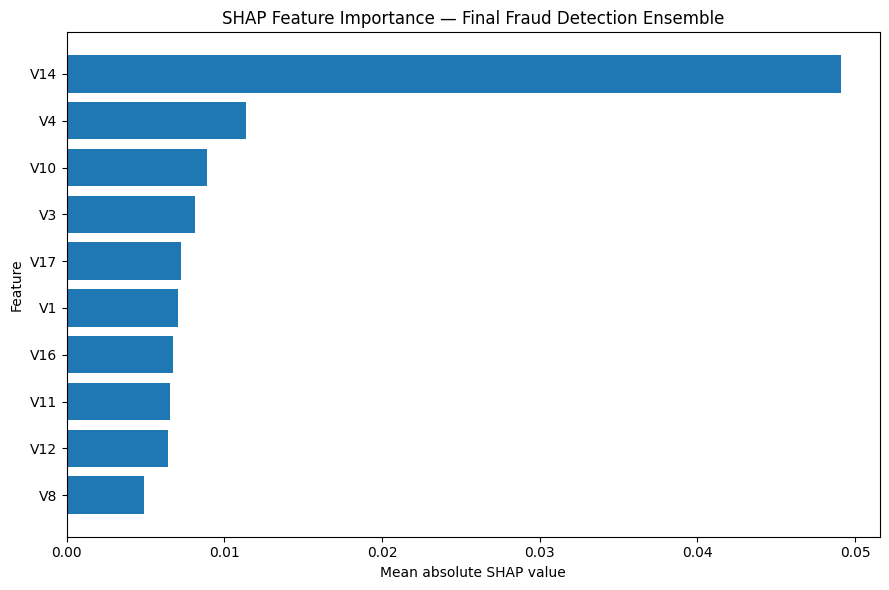

,Feature,Mean_Absolute_SHAP
0,V14,0.049121
1,V4,0.011351
2,V10,0.008890
3,V3,0.008135
4,V17,0.007228
5,V1,0.007078
6,V16,0.006729
7,V11,0.006586
8,V12,0.006412
9,V8,0.004902


In [37]:
import pandas as pd
import matplotlib.pyplot as plt

shap_importance = pd.DataFrame({
    "Feature": selected_features,
    "Mean_Absolute_SHAP": np.abs(shap_values).mean(axis=0)
}).sort_values("Mean_Absolute_SHAP", ascending=True)

plt.figure(figsize=(9, 6))
plt.barh(
    shap_importance["Feature"],
    shap_importance["Mean_Absolute_SHAP"]
)
plt.xlabel("Mean absolute SHAP value")
plt.ylabel("Feature")
plt.title("SHAP Feature Importance — Final Fraud Detection Ensemble")
plt.tight_layout()
plt.show()

display(shap_importance.sort_values(
    "Mean_Absolute_SHAP", ascending=False
).reset_index(drop=True))

## Explaining individual predictions

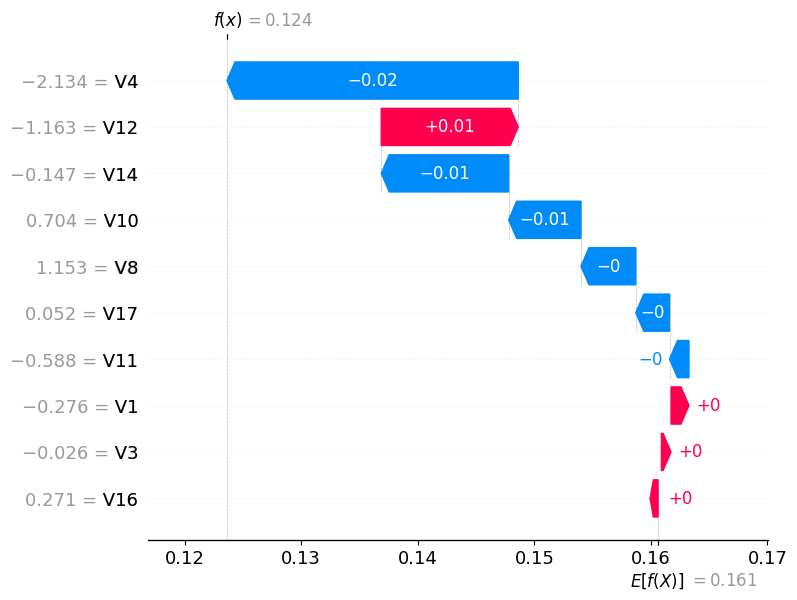

In [39]:

import numpy as np
import shap
import matplotlib.pyplot as plt

base_values = np.asarray(explainer.expected_value)
base_value = float(base_values.reshape(-1)[0])

explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(len(shap_values), base_value),
    data=explain_data,
    feature_names=selected_features
)

shap.plots.waterfall(
    explanation[0],
    max_display=10,
    show=True
)